# Prototipo Libre (Práctica 5): J.A.R.V.I.S. / Iron-Man Biometric HUD

Este cuaderno implementa el **prototipo libre de biometría facial en tiempo real** inspirado en el visor HUD de **Iron-Man / J.A.R.V.I.S.**, proyectado directamente sobre el rostro del usuario.

### Capacidades biométricas integradas
1. **Eye Aspect Ratio (EAR)**: Detección de parpadeos, frecuencia (**BPM**) y alarma por **microsueño**.
2. **Mouth Aspect Ratio (MAR)**: Detección de **bostezos** y fatiga acumulada.
3. **Estimación de Pose 3D (`cv2.solvePnP`)**: Mapeo 2D↔3D para calcular **Pitch / Yaw / Roll**, proyectar ejes/frustum 3D (`cv2.projectPoints`) y detectar **distracción** o **cabeceo**.
4. **Motor de Emoción y Estrés**: Gancho directo para modelo entrenado propio (`.joblib`/`.pkl`/`.onnx`), fusión asíncrona opcional con `DeepFace` y clasificador en tiempo real mediante **52 Blendshapes de MediaPipe**.
5. **Alarma Visual y Sonora**: Parpadeo en rojo carmesí + banner de alerta + kláxon dual-tono sintetizado de forma asíncrona ante **microsueño/cabeceo** o **estrés elevado**.

### Controles en modo Webcam
| Tecla | Acción |
| :--- | :--- |
| `q` o `ESC` | Salir del HUD |
| `c` | Calibrar pose neutral (Pitch/Yaw/Roll a 0°) |
| `m` | Silenciar / activar alarma sonora |
| `t` | Cambiar estilo de malla holográfica (`TACTICAL` / `FULL_MESH` / `MINIMAL`) |
| `s` | Ciclar estado simulado (`LIVE` → `NOD` → `STRESS`) para pruebas |
| `r` | Iniciar / detener grabación de GIF demo (máx. 30 s) |


In [1]:
import os
import sys
import math
import time
import wave
import shutil
import pickle
import threading
import subprocess
import urllib.request
from collections import deque
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Tuple

# Evita errores en directorios de configuración de solo lectura
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl_cache")
os.environ.setdefault("DEEPFACE_HOME", os.path.abspath("./.deepface_cache"))

import cv2
import joblib
import imageio.v2 as imageio
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt


In [2]:
@dataclass
class HUDConfig:
    model_path: str = "face_landmarker.task"
    custom_emotion_model_path: Optional[str] = None
    use_deepface: bool = False  # Activar True para fusión asíncrona con DeepFace

    # Parámetros EAR (Eye Aspect Ratio)
    ear_threshold: float = 0.21
    ear_consec_frames_blink: int = 2
    micro_sleep_seconds: float = 1.2
    ear_ema_alpha: float = 0.55

    # Parámetros MAR (Mouth Aspect Ratio)
    mar_threshold: float = 0.55
    yawn_seconds: float = 1.0
    mar_ema_alpha: float = 0.45

    # Parámetros Pose 3D (cv2.solvePnP) en grados
    pitch_nod_threshold: float = -18.0
    pitch_up_threshold: float = 25.0
    yaw_look_away_threshold: float = 28.0
    pose_alert_seconds: float = 1.0
    pose_ema_alpha: float = 0.40

    # Parámetros Emoción y Estrés
    stress_threshold: float = 0.52
    stress_alert_seconds: float = 1.0
    stress_ema_alpha: float = 0.35
    deepface_interval_seconds: float = 0.75

    # Alarma sonora e historial visual
    alarm_wav_path: str = "jarvis_alarm.wav"
    alarm_cooldown_seconds: float = 1.8
    history_len: int = 72


FACE_LANDMARKER_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/face_landmarker.task"
)


def ensure_face_landmarker_model(model_path: str = "face_landmarker.task") -> str:
    '''Descarga face_landmarker.task si no existe localmente.'''
    path = Path(model_path)
    if path.exists() and path.stat().st_size > 100_000:
        return str(path)
    print(f"Descargando modelo MediaPipe FaceLandmarker en {path}...")
    urllib.request.urlretrieve(FACE_LANDMARKER_URL, str(path))
    print(f"Modelo descargado ({path.stat().st_size / 1e6:.2f} MB).")
    return str(path)


CONFIG = HUDConfig()
ensure_face_landmarker_model(CONFIG.model_path)
print(f"Entorno listo | Python {sys.version.split()[0]} | OpenCV {cv2.__version__} | MediaPipe {mp.__version__}")


Entorno listo | Python 3.11.9 | OpenCV 5.1.0 | MediaPipe 1.2.3


## 1. Motor Biométrico: Geometría Facial (EAR/MAR) y Pose 3D (`cv2.solvePnP`)
Separado en tres capas:
- **Primitivas geométricas**: distancias, suavizado EMA, extracción de puntos 2D, `compute_ear` y `compute_mar`.
- **Solver 3D**: construcción de matriz de cámara, `solve_head_pose_pnp` y proyección `project_3d_points`.
- **Orquestador (`BiometricTracker`)**: mantiene historiales, contadores y temporizadores de alerta.


In [3]:
# Índices de landmarks MediaPipe (478 puntos con refinamiento de iris)
RIGHT_EYE_IDXS = [33, 160, 158, 133, 153, 144]   # Ojo derecho del sujeto
LEFT_EYE_IDXS = [362, 385, 387, 263, 373, 380]   # Ojo izquierdo del sujeto
RIGHT_IRIS_IDX = 468
LEFT_IRIS_IDX = 473

MOUTH_CORNERS = (61, 291)
MOUTH_VERT_PAIRS = [(81, 178), (13, 14), (311, 402)]

# 6 puntos faciales para PnP: Nariz, Mentón, Ojo izq. ext, Ojo der. ext, Comisura izq., Comisura der.
PNP_LANDMARK_IDXS = [1, 152, 263, 33, 291, 61]

# Modelo antropométrico 3D canónico (+X derecha, +Y abajo, +Z profundidad)
MODEL_3D_POINTS = np.array([
    (0.0, 0.0, 0.0),          # Nariz (1)
    (0.0, 330.0, 65.0),       # Mentón (152)
    (225.0, -170.0, 135.0),   # Ojo izq. externo (263)
    (-225.0, -170.0, 135.0),  # Ojo der. externo (33)
    (150.0, 150.0, 125.0),    # Comisura izq. (291)
    (-150.0, 150.0, 125.0),   # Comisura der. (61)
], dtype=np.float64)

# Frustum holográfico 3D proyectado alrededor del rostro
VISOR_BOX_3D = np.array([
    (-320.0, -340.0, 190.0), (320.0, -340.0, 190.0), (320.0, 380.0, 190.0), (-320.0, 380.0, 190.0),
    (-270.0, -290.0, -110.0), (270.0, -290.0, -110.0), (270.0, 320.0, -110.0), (-270.0, 320.0, -110.0),
], dtype=np.float64)


def _euclid(a: np.ndarray, b: np.ndarray) -> float:
    return float(np.linalg.norm(a - b))


def _ema(prev, curr, alpha: float):
    if prev is None:
        return curr
    return alpha * curr + (1.0 - alpha) * prev


def extract_landmarks_2d(face_landmarks, width: int, height: int) -> np.ndarray:
    return np.array([[lm.x * width, lm.y * height] for lm in face_landmarks], dtype=np.float64)


def compute_bbox(pts_2d: np.ndarray, width: int, height: int) -> Tuple[int, int, int, int]:
    x1 = int(np.clip(np.min(pts_2d[:, 0]), 0, width - 1))
    y1 = int(np.clip(np.min(pts_2d[:, 1]), 0, height - 1))
    x2 = int(np.clip(np.max(pts_2d[:, 0]), 0, width - 1))
    y2 = int(np.clip(np.max(pts_2d[:, 1]), 0, height - 1))
    return (x1, y1, x2, y2)


def compute_ear(pts_2d: np.ndarray, eye_indices: List[int]) -> float:
    p1, p2, p3, p4, p5, p6 = [pts_2d[i] for i in eye_indices]
    horiz = _euclid(p1, p4)
    return 0.0 if horiz < 1e-6 else (_euclid(p2, p6) + _euclid(p3, p5)) / (2.0 * horiz)


def compute_mar(pts_2d: np.ndarray) -> float:
    horiz = _euclid(pts_2d[MOUTH_CORNERS[0]], pts_2d[MOUTH_CORNERS[1]])
    if horiz < 1e-6:
        return 0.0
    vert_avg = sum(_euclid(pts_2d[a], pts_2d[b]) for a, b in MOUTH_VERT_PAIRS) / len(MOUTH_VERT_PAIRS)
    return vert_avg / horiz


In [4]:
def build_camera_matrix(width: int, height: int) -> np.ndarray:
    focal = float(width)
    return np.array(
        [[focal, 0.0, width / 2.0], [0.0, focal, height / 2.0], [0.0, 0.0, 1.0]],
        dtype=np.float64,
    )


def rotation_matrix_to_euler(rmat: np.ndarray) -> Tuple[float, float, float]:
    '''Convierte matriz de rotación a (pitch, yaw, roll) en grados desde el eje frontal nasal.'''
    nose_fwd = rmat @ np.array([0.0, 0.0, -1.0], dtype=np.float64)
    pitch = float(np.degrees(np.arcsin(np.clip(-nose_fwd[1], -1.0, 1.0))))
    yaw = float(np.degrees(np.arctan2(nose_fwd[0], -nose_fwd[2])))
    roll = float(np.degrees(np.arctan2(rmat[1, 0], rmat[0, 0])))
    return pitch, yaw, roll


def solve_head_pose_pnp(
    pts_2d: np.ndarray, width: int, height: int
) -> Tuple[float, float, float, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    '''Estima rotación/traslación 3D de la cabeza mediante cv2.solvePnP.'''
    image_points = pts_2d[PNP_LANDMARK_IDXS].astype(np.float64)
    cam_matrix = build_camera_matrix(width, height)
    dist_coeffs = np.zeros((4, 1), dtype=np.float64)

    ok, rvec, tvec = cv2.solvePnP(
        MODEL_3D_POINTS, image_points, cam_matrix, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE
    )
    if not ok or tvec[2, 0] < 0:
        _, rvec, tvec = cv2.solvePnP(
            MODEL_3D_POINTS, image_points, cam_matrix, dist_coeffs, flags=cv2.SOLVEPNP_EPNP
        )

    rmat, _ = cv2.Rodrigues(rvec)
    pitch, yaw, roll = rotation_matrix_to_euler(rmat)
    return pitch, yaw, roll, rvec, tvec, cam_matrix, dist_coeffs


def project_3d_points(points_3d: np.ndarray, bio: "BiometricState", scale_xy: float) -> np.ndarray:
    '''Proyecta puntos 3D del modelo craneal al plano 2D del lienzo HUD.'''
    proj, _ = cv2.projectPoints(points_3d, bio.rvec, bio.tvec, bio.cam_matrix, bio.dist_coeffs)
    return proj.reshape(-1, 2) * scale_xy


In [5]:
@dataclass
class BiometricState:
    timestamp: float = 0.0
    face_detected: bool = False
    pts_2d: Optional[np.ndarray] = None
    bbox: Tuple[int, int, int, int] = (0, 0, 0, 0)

    ear_left: float = 0.0
    ear_right: float = 0.0
    ear_raw: float = 0.0
    ear: float = 0.0
    eye_closed: bool = False
    eye_closed_duration: float = 0.0
    blink_count: int = 0
    blink_rate_bpm: float = 0.0
    micro_sleep: bool = False

    mar_raw: float = 0.0
    mar: float = 0.0
    mouth_open: bool = False
    mouth_open_duration: float = 0.0
    yawn_count: int = 0
    yawning: bool = False

    raw_pitch: float = 0.0
    raw_yaw: float = 0.0
    raw_roll: float = 0.0
    pitch: float = 0.0
    yaw: float = 0.0
    roll: float = 0.0
    rvec: Optional[np.ndarray] = None
    tvec: Optional[np.ndarray] = None
    cam_matrix: Optional[np.ndarray] = None
    dist_coeffs: Optional[np.ndarray] = None
    nodding_off: bool = False
    nod_duration: float = 0.0
    looking_away: bool = False
    look_away_duration: float = 0.0

    ear_history: List[float] = field(default_factory=list)
    mar_history: List[float] = field(default_factory=list)


class BiometricTracker:
    '''Rastreador biométrico modular para EAR, MAR y Pose 3D.'''

    def __init__(self, config: HUDConfig):
        self.cfg = config
        self.reset()

    def reset(self) -> None:
        self._ear_ema: Optional[float] = None
        self._mar_ema: Optional[float] = None
        self._pose_ema: Optional[np.ndarray] = None
        self._pose_offset = np.zeros(3, dtype=np.float64)
        self._last_raw_pose = np.zeros(3, dtype=np.float64)

        self._closed_frames = 0
        self._eye_closed_start: Optional[float] = None
        self._blink_timestamps: deque = deque()
        self.blink_count = 0

        self._mouth_open_start: Optional[float] = None
        self._yawn_counted = False
        self.yawn_count = 0

        self._nod_start: Optional[float] = None
        self._away_start: Optional[float] = None
        self.ear_history: deque = deque(maxlen=self.cfg.history_len)
        self.mar_history: deque = deque(maxlen=self.cfg.history_len)

    def calibrate_pose(self) -> np.ndarray:
        self._pose_offset = self._last_raw_pose.copy()
        self._pose_ema = np.zeros(3, dtype=np.float64)
        return self._pose_offset

    def _update_ocular_metrics(self, state: BiometricState, pts_2d: np.ndarray, now: float) -> None:
        state.ear_left = compute_ear(pts_2d, LEFT_EYE_IDXS)
        state.ear_right = compute_ear(pts_2d, RIGHT_EYE_IDXS)
        state.ear_raw = 0.5 * (state.ear_left + state.ear_right)
        self._ear_ema = _ema(self._ear_ema, state.ear_raw, self.cfg.ear_ema_alpha)
        state.ear = float(self._ear_ema)
        self.ear_history.append(state.ear)
        self._update_blink_counter(state, now)

    def _update_blink_counter(self, state: BiometricState, now: float) -> None:
        if state.ear_raw < self.cfg.ear_threshold:
            self._closed_frames += 1
            if self._eye_closed_start is None:
                self._eye_closed_start = now
                
            state.eye_closed = True
            state.eye_closed_duration = now - self._eye_closed_start
            state.micro_sleep = state.eye_closed_duration >= self.cfg.micro_sleep_seconds
        else:
            if self._closed_frames >= self.cfg.ear_consec_frames_blink:
                self.blink_count += 1
                self._blink_timestamps.append(now)
                
            self._closed_frames = 0
            self._eye_closed_start = None

        while self._blink_timestamps and (now - self._blink_timestamps[0]) > 60.0:
            self._blink_timestamps.popleft()
            
        state.blink_count = self.blink_count
        state.blink_rate_bpm = float(len(self._blink_timestamps))

    def _update_oral_metrics(self, state: BiometricState, pts_2d: np.ndarray, now: float) -> None:
        state.mar_raw = compute_mar(pts_2d)
        self._mar_ema = _ema(self._mar_ema, state.mar_raw, self.cfg.mar_ema_alpha)
        state.mar = float(self._mar_ema)
        self.mar_history.append(state.mar)

        if state.mar > self.cfg.mar_threshold:
            if self._mouth_open_start is None:
                self._mouth_open_start = now
                
            state.mouth_open = True
            state.mouth_open_duration = now - self._mouth_open_start
            
            if state.mouth_open_duration >= self.cfg.yawn_seconds:
                state.yawning = True
                if not self._yawn_counted:
                    self.yawn_count += 1
                    self._yawn_counted = True
        else:
            self._mouth_open_start = None
            self._yawn_counted = False
            
        state.yawn_count = self.yawn_count

    def _update_pose_metrics(self, state: BiometricState, pts_2d: np.ndarray, w: int, h: int, now: float) -> None:
        raw_p, raw_y, raw_r, rvec, tvec, cam_mat, dist = solve_head_pose_pnp(pts_2d, w, h)
        raw_vec = np.array([raw_p, raw_y, raw_r], dtype=np.float64)
        self._last_raw_pose = raw_vec
        self._pose_ema = _ema(self._pose_ema, raw_vec - self._pose_offset, self.cfg.pose_ema_alpha)

        state.raw_pitch, state.raw_yaw, state.raw_roll = raw_p, raw_y, raw_r
        state.pitch, state.yaw, state.roll = map(float, self._pose_ema)
        state.rvec, state.tvec, state.cam_matrix, state.dist_coeffs = rvec, tvec, cam_mat, dist
        self._update_attention_flags(state, now)

    def _update_attention_flags(self, state: BiometricState, now: float) -> None:
        if state.pitch <= self.cfg.pitch_nod_threshold:
            if self._nod_start is None:
                self._nod_start = now
                
            state.nod_duration = now - self._nod_start
            state.nodding_off = state.nod_duration >= self.cfg.pose_alert_seconds
        else:
            self._nod_start = None

        is_away = abs(state.yaw) >= self.cfg.yaw_look_away_threshold or state.pitch >= self.cfg.pitch_up_threshold
        if is_away:
            if self._away_start is None:
                self._away_start = now
            
            state.look_away_duration = now - self._away_start
            state.looking_away = state.look_away_duration >= self.cfg.pose_alert_seconds
        else:
            self._away_start = None

    def update(self, face_landmarks, frame_shape: Tuple[int, ...], now: Optional[float] = None) -> BiometricState:
        now = time.monotonic() if now is None else now
        h, w = frame_shape[:2]
        state = BiometricState(timestamp=now, blink_count=self.blink_count, yawn_count=self.yawn_count)

        if not face_landmarks:
            self.ear_history.append(0.0)
            self.mar_history.append(0.0)
        else:
            pts_2d = extract_landmarks_2d(face_landmarks, w, h)
            state.face_detected = True
            state.pts_2d = pts_2d
            state.bbox = compute_bbox(pts_2d, w, h)
            self._update_ocular_metrics(state, pts_2d, now)
            self._update_oral_metrics(state, pts_2d, now)
            self._update_pose_metrics(state, pts_2d, w, h, now)

        state.ear_history = list(self.ear_history)
        state.mar_history = list(self.mar_history)
        return state


## 2. Motor de Emoción y Estrés
Dividido en:
- **Utilidades de características y Blendshapes** (`crop_face_roi`, `extract_face_features`, `blendshapes_to_emotion_scores`).
- **Adaptadores enchufables** (`CustomEmotionModelAdapter` para modelos propios `.joblib`/`.pkl`/`.onnx` y `AsyncDeepFaceWorker`).
- **Orquestador (`EmotionEngine`)**: fusiona los backends disponibles y controla el temporizador de estrés sostenido.


In [6]:
STANDARD_EMOTIONS = ["angry", "fear", "happy", "neutral", "sad", "surprise"]


@dataclass
class EmotionState:
    dominant_emotion: str = "neutral"
    confidence: float = 0.0
    scores: Dict[str, float] = field(default_factory=lambda: {k: 0.0 for k in STANDARD_EMOTIONS})
    stress_index: float = 0.0
    is_stressed: bool = False
    stress_duration: float = 0.0
    backend: str = "MP-BLENDSHAPES"


def _softmax(vec: np.ndarray) -> np.ndarray:
    e = np.exp(vec - np.max(vec))
    return e / np.maximum(e.sum(), 1e-9)


def crop_face_roi(frame: np.ndarray, bbox: Tuple[int, int, int, int], pad: float = 0.12) -> Optional[np.ndarray]:
    h, w = frame.shape[:2]
    x1, y1, x2, y2 = bbox
    bw, bh = x2 - x1, y2 - y1
    if bw < 20 or bh < 20:
        return None
    px, py = int(bw * pad), int(bh * pad)
    return frame[max(0, y1 - py):min(h, y2 + py), max(0, x1 - px):min(w, x2 + px)]


def extract_face_features(
    face_bgr: np.ndarray, image_size: Tuple[int, int], feature_type: str = "pixels", pca=None, scaler=None
) -> np.ndarray:
    '''Extrae píxeles, HOG o LBP de un rostro recortado para clasificadores sklearn.'''
    gray = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, image_size, interpolation=cv2.INTER_AREA)

    if feature_type == "hog":
        from skimage.feature import hog
        feat = hog(resized, orientations=8, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
    elif feature_type == "lbp":
        from skimage.feature import local_binary_pattern
        lbp = local_binary_pattern(resized, P=8, R=1, method="nri_uniform")
        feat, _ = np.histogram(lbp.ravel(), bins=59, range=(0, 59), density=True)
    else:
        feat = resized.astype(np.float32).reshape(-1) / 255.0

    X = feat.reshape(1, -1)
    if pca is not None:
        X = pca.transform(X)
    if scaler is not None:
        X = scaler.transform(X)
    return X


def blendshapes_to_emotion_scores(blendshapes) -> Tuple[Dict[str, float], float]:
    '''Convierte los 52 Action Units de MediaPipe en probabilidades emocionales y estrés.'''
    if not blendshapes:
        return {k: (1.0 if k == "neutral" else 0.0) for k in STANDARD_EMOTIONS}, 0.0

    bs = {b.category_name: float(b.score) for b in blendshapes}
    avg = lambda a, b: 0.5 * (bs.get(a, 0.0) + bs.get(b, 0.0))

    smile = avg("mouthSmileLeft", "mouthSmileRight")
    brow_down = avg("browDownLeft", "browDownRight")
    brow_inner = bs.get("browInnerUp", 0.0)
    brow_outer = avg("browOuterUpLeft", "browOuterUpRight")
    eye_wide = avg("eyeWideLeft", "eyeWideRight")
    eye_squint = avg("eyeSquintLeft", "eyeSquintRight")
    frown = avg("mouthFrownLeft", "mouthFrownRight")
    press = avg("mouthPressLeft", "mouthPressRight")
    stretch = avg("mouthStretchLeft", "mouthStretchRight")
    sneer = avg("noseSneerLeft", "noseSneerRight")
    jaw_open = bs.get("jawOpen", 0.0)

    non_smile = max(0.0, 1.0 - 1.15 * smile)
    raw = {
        "happy": 0.90 * smile + 0.15 * eye_squint * smile,
        "angry": non_smile * (0.50 * brow_down + 0.30 * press + 0.25 * sneer + 0.20 * eye_squint + 0.15 * frown),
        "fear": non_smile * (0.45 * eye_wide + 0.30 * brow_inner + 0.25 * stretch + 0.15 * jaw_open),
        "sad": non_smile * (0.45 * frown + 0.35 * brow_inner + 0.20 * press),
        "surprise": max(0.0, 0.45 * eye_wide + 0.35 * brow_outer + 0.35 * jaw_open - 0.20 * brow_down),
    }
    raw["neutral"] = max(0.05, 0.55 - max(raw.values()))

    total = max(sum(raw.values()), 1e-9)
    probs = {k: v / total for k, v in raw.items()}

    au_tension = non_smile * (0.45 * brow_down + 0.35 * press + 0.30 * frown + 0.25 * eye_wide + 0.20 * sneer)
    emo_neg = probs["angry"] + probs["fear"] + 0.75 * probs["sad"]
    return probs, float(np.clip(0.55 * emo_neg + 0.65 * au_tension, 0.0, 1.0))


In [7]:
class CustomEmotionModelAdapter:
    '''Carga y ejecuta un modelo entrenado propio (sklearn .joblib/.pkl u .onnx).'''

    DEFAULT_CANDIDATES = (
        "emotion_model.joblib", "emotion_model.pkl",
        "models/emotion_model.joblib", "models/emotion_model.pkl",
        "emotion_model.onnx",
    )

    def __init__(self, model_path: Optional[str] = None):
        self.model_path: Optional[str] = None
        self.kind: Optional[str] = None
        self.estimator = self.scaler = self.pca = None
        self.feature_type = "pixels"
        self.image_size = (59, 65)
        self.class_names: Optional[List[str]] = None
        self.ort_session = self.ort_input_name = None

        resolved = self._resolve_path(model_path)
        if resolved is not None:
            self._load_onnx(resolved) if resolved.endswith(".onnx") else self._load_sklearn(resolved)

    @property
    def is_loaded(self) -> bool:
        return self.kind is not None

    def _resolve_path(self, model_path: Optional[str]) -> Optional[str]:
        if model_path and Path(model_path).exists():
            return model_path
        
        return next((c for c in self.DEFAULT_CANDIDATES if Path(c).exists()), None)

    def _load_onnx(self, path: str) -> None:
        import onnxruntime as ort
        self.model_path, self.kind = path, "onnx"
        self.ort_session = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
        self.ort_input_name = self.ort_session.get_inputs()[0].name

    def _load_sklearn(self, path: str) -> None:
        self.model_path, self.kind = path, "sklearn"
        payload = joblib.load(path) if path.endswith(".joblib") else pickle.load(open(path, "rb"))
        if isinstance(payload, dict) and "model" in payload:
            self.estimator = payload["model"]
            self.scaler = payload.get("scaler")
            self.pca = payload.get("pca")
            self.feature_type = payload.get("feature_type", "pixels")
            self.image_size = tuple(payload.get("image_size", self.image_size))
            self.class_names = payload.get("class_names")
            return

        self.estimator = payload
        if hasattr(self.estimator, "classes_"):
            self.class_names = [str(c).lower() for c in self.estimator.classes_]
            
        size_map = {59 * 65: (59, 65), 48 * 48: (48, 48), 64 * 64: (64, 64)}
        self.image_size = size_map.get(getattr(self.estimator, "n_features_in_", None), self.image_size)

    def _predict_onnx(self, face_bgr: np.ndarray) -> Dict[str, float]:
        shape = self.ort_session.get_inputs()[0].shape
        h = shape[1] if isinstance(shape[1], int) and shape[1] > 8 else 48
        w = shape[2] if len(shape) > 2 and isinstance(shape[2], int) and shape[2] > 8 else 48
        resized = cv2.resize(cv2.cvtColor(face_bgr, cv2.COLOR_BGR2GRAY), (w, h)).astype(np.float32) / 255.0
        tensor = resized.reshape(1, h, w, 1) if len(shape) == 4 and shape[-1] == 1 else resized.reshape(1, 1, h, w)
        probs = _softmax(np.asarray(self.ort_session.run(None, {self.ort_input_name: tensor})[0]).ravel())
        labels = self.class_names or (STANDARD_EMOTIONS + ["disgust"])[: len(probs)]
        
        return {str(lbl).lower(): float(p) for lbl, p in zip(labels, probs)}

    def _predict_sklearn(self, face_bgr: np.ndarray) -> Dict[str, float]:
        X = extract_face_features(face_bgr, self.image_size, self.feature_type, self.pca, self.scaler)
        labels = self.class_names or [str(c).lower() for c in getattr(self.estimator, "classes_", STANDARD_EMOTIONS)]
        if hasattr(self.estimator, "predict_proba"):
            probs = self.estimator.predict_proba(X)[0]
        elif hasattr(self.estimator, "decision_function"):
            df = np.atleast_1d(self.estimator.decision_function(X)).ravel()
            probs = np.array([1.0 - 1.0 / (1.0 + np.exp(-df[0])), 1.0 / (1.0 + np.exp(-df[0]))]) if (df.size == 1 and len(labels) == 2) else _softmax(df)
        else:
            pred = str(self.estimator.predict(X)[0]).lower()
            probs = np.array([1.0 if lbl == pred else 0.0 for lbl in labels], dtype=np.float64)
            
        return {str(lbl).lower(): float(p) for lbl, p in zip(labels, probs)}

    def predict(self, face_bgr: Optional[np.ndarray]) -> Optional[Dict[str, float]]:
        if not self.is_loaded or face_bgr is None or face_bgr.size == 0:
            return None
        
        return self._predict_onnx(face_bgr) if self.kind == "onnx" else self._predict_sklearn(face_bgr)


class AsyncDeepFaceWorker:
    '''Ejecuta DeepFace.analyze en segundo plano sin bloquear el flujo de vídeo.'''

    def __init__(self, interval_seconds: float = 0.75):
        self.interval_seconds = interval_seconds
        self._lock = threading.Lock()
        self._latest_scores: Optional[Dict[str, float]] = None
        self._running = False
        self._last_submit = 0.0
        self._available = True
        self._deepface = None

    def _ensure_import(self) -> bool:
        if self._deepface is not None or not self._available:
            return self._available
        try:
            from deepface import DeepFace
            self._deepface = DeepFace
            return True
        except Exception:
            self._available = False
            return False

    def maybe_submit(self, face_bgr: np.ndarray, now: float) -> Optional[Dict[str, float]]:
        if self._available and not self._running and (now - self._last_submit) >= self.interval_seconds:
            if face_bgr is not None and face_bgr.size > 0 and self._ensure_import():
                self._running = True
                self._last_submit = now
                threading.Thread(target=self._run, args=(face_bgr.copy(),), daemon=True).start()
                
        with self._lock:
            return dict(self._latest_scores) if self._latest_scores is not None else None

    def _run(self, crop: np.ndarray) -> None:
        try:
            # En OpenCV 5.1 no existe CascadeClassifier: usamos detector_backend='skip' con recorte MediaPipe
            res = self._deepface.analyze(
                img_path=crop, actions=["emotion"], detector_backend="skip", enforce_detection=False, silent=True
            )
            emo_dict = res[0]["emotion"] if isinstance(res, list) else res["emotion"]
            with self._lock:
                self._latest_scores = {k.lower(): float(v) / 100.0 for k, v in emo_dict.items()}
        except Exception:
            self._available = False
        finally:
            self._running = False


In [8]:
class EmotionEngine:
    '''Orquesta el modelo propio, DeepFace opcional y Blendshapes de MediaPipe.'''

    NEG_EMOTIONS = ("angry", "fear", "sad", "disgust", "stressed")

    def __init__(self, config: HUDConfig):
        self.cfg = config
        self.custom_model = CustomEmotionModelAdapter(config.custom_emotion_model_path)
        self.deepface_worker = AsyncDeepFaceWorker(config.deepface_interval_seconds) if config.use_deepface else None
        self._stress_ema = 0.0
        self._stress_start: Optional[float] = None

    def _evaluate_model_backends(
        self, frame: np.ndarray, bbox: Tuple[int, int, int, int], bs_probs: Dict[str, float], bs_stress: float, now: float
    ) -> Tuple[Dict[str, float], float, str]:
        face_roi = crop_face_roi(frame, bbox)
        if self.custom_model.is_loaded and face_roi is not None:
            custom_probs = self.custom_model.predict(face_roi)
            if custom_probs:
                neg = sum(custom_probs.get(k, 0.0) for k in self.NEG_EMOTIONS)
                return custom_probs, float(np.clip(0.65 * neg + 0.35 * bs_stress, 0.0, 1.0)), f"CUSTOM ({Path(self.custom_model.model_path).name})"

        if self.deepface_worker is not None and face_roi is not None:
            df_probs = self.deepface_worker.maybe_submit(face_roi, now)
            if df_probs:
                keys = set(bs_probs) | set(df_probs)
                fused = {k: 0.65 * df_probs.get(k, 0.0) + 0.35 * bs_probs.get(k, 0.0) for k in keys}
                neg = sum(fused.get(k, 0.0) for k in self.NEG_EMOTIONS)
                return fused, float(np.clip(0.65 * neg + 0.35 * bs_stress, 0.0, 1.0)), "DEEPFACE+MP"

        return bs_probs, bs_stress, "MP-BLENDSHAPES"

    def _update_stress_timer(self, now: float) -> Tuple[bool, float]:
        if self._stress_ema < self.cfg.stress_threshold:
            self._stress_start = None
            return False, 0.0
        if self._stress_start is None:
            self._stress_start = now
        dur = now - self._stress_start
        return dur >= self.cfg.stress_alert_seconds, dur

    def update(self, frame: np.ndarray, bbox: Tuple[int, int, int, int], blendshapes, now: Optional[float] = None) -> EmotionState:
        now = time.monotonic() if now is None else now
        bs_probs, bs_stress = blendshapes_to_emotion_scores(blendshapes)
        probs, stress_raw, backend = self._evaluate_model_backends(frame, bbox, bs_probs, bs_stress, now)

        self._stress_ema = float(_ema(self._stress_ema, stress_raw, self.cfg.stress_ema_alpha))
        is_stressed, stress_dur = self._update_stress_timer(now)
        dom, conf = max(probs.items(), key=lambda kv: kv[1])
        return EmotionState(
            dominant_emotion=dom,
            confidence=float(conf),
            scores=probs,
            stress_index=self._stress_ema,
            is_stressed=is_stressed,
            stress_duration=stress_dur,
            backend=backend,
        )


## 3. Sistema de Alarma Sonora Asíncrona
Sintetiza un kláxon dual-tono estilo J.A.R.V.I.S. en `.wav` y lo reproduce en un subproceso no bloqueante con control de *cooldown* y silenciamiento (`mute`).


In [9]:
def synthesize_jarvis_alarm_wav(wav_path: str) -> None:
    '''Genera un pulso doble de alerta futurista (880 Hz + 1320 Hz FM) en formato WAV PCM.'''
    if Path(wav_path).exists() and Path(wav_path).stat().st_size > 1000:
        return
    sr, dur = 44100, 0.46
    t = np.linspace(0.0, dur, int(sr * dur), endpoint=False)
    env = np.clip((t < 0.18).astype(np.float64) + ((t >= 0.24) & (t < 0.44)).astype(np.float64), 0.0, 1.0)
    env = np.convolve(env, np.ones(220) / 220.0, mode="same")

    carrier = 0.55 * np.sin(2.0 * np.pi * 880.0 * t + 1.5 * np.sin(2.0 * np.pi * 18.0 * t))
    harmonic = 0.35 * np.sin(2.0 * np.pi * 1320.0 * t)
    pcm = (np.clip((carrier + harmonic) * env * 0.65, -1.0, 1.0) * 32767.0).astype(np.int16)

    with wave.open(wav_path, "wb") as wf:
        wf.setnchannels(1)
        wf.setsampwidth(2)
        wf.setframerate(sr)
        wf.writeframes(pcm.tobytes())


class AudioAlarm:
    '''Gestor no bloqueante de alarma sonora con cooldown y mute.'''

    PLAYERS = (("paplay", []), ("pw-play", []), ("aplay", ["-q"]), ("ffplay", ["-nodisp", "-autoexit", "-loglevel", "quiet"]))

    def __init__(self, wav_path: str = "jarvis_alarm.wav", cooldown_seconds: float = 1.8):
        self.wav_path = wav_path
        self.cooldown_seconds = cooldown_seconds
        self.muted = False
        self._last_trigger = 0.0
        self._player_cmd = next(([shutil.which(cmd)] + args for cmd, args in self.PLAYERS if shutil.which(cmd)), None)
        synthesize_jarvis_alarm_wav(self.wav_path)

    def trigger(self, now: Optional[float] = None) -> bool:
        now = time.monotonic() if now is None else now
        if self.muted or (now - self._last_trigger) < self.cooldown_seconds:
            return False
        self._last_trigger = now

        if self._player_cmd is not None:
            try:
                subprocess.Popen(self._player_cmd + [self.wav_path], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
                return True
            except Exception:
                pass
        print("\a", end="", flush=True)
        return True


## 4. Renderizador HUD Futurista (Iron-Man / J.A.R.V.I.S.)
Organizado por capas:
1. **Paleta y primitivas gráficas**: resolución de estado (`HUDTheme`), paneles translúcidos, barras de progreso, *sparklines*, retículas oculares y radar de actitud.
2. **Capas sobre el rostro**: malla holográfica, calibradores bucales y proyección 3D (`cv2.projectPoints`).
3. **Paneles periféricos y alerta roja**: cabecera, panel ocular/oral izquierdo, panel de pose/emoción derecho y viñeta parpadeante de alarma crítica.
4. **Clase `IronManHUDRenderer`**: ensamblado final en `render()`.


In [1]:
FaceConns = mp.tasks.vision.FaceLandmarksConnections


@dataclass
class HUDTheme:
    primary: Tuple[int, int, int]
    text_primary: Tuple[int, int, int]
    secondary: Tuple[int, int, int]
    accent: Tuple[int, int, int]
    status_text: str
    alarm_active: bool
    alarm_reasons: List[str]
    flash: float


def collect_alarm_reasons(bio: BiometricState, emo: EmotionState) -> List[str]:
    reasons = []
    if bio.micro_sleep:
        reasons.append("MICRO-SLEEP DETECTED")
    if bio.nodding_off:
        reasons.append("HEAD NODDING OFF")
    if emo.is_stressed:
        reasons.append("HIGH STRESS DETECTED")
    return reasons


def resolve_hud_theme(bio: BiometricState, emo: EmotionState, now: float) -> HUDTheme:
    reasons = collect_alarm_reasons(bio, emo)
    flash = 0.5 + 0.5 * math.sin(now * 14.0)
    if reasons:
        c_hi, c_lo = np.array([50, 50, 255], np.float32), np.array([25, 25, 175], np.float32)
        primary = tuple(int(v) for v in (c_lo + flash * (c_hi - c_lo)))
        return HUDTheme(primary, (120, 125, 255), (35, 35, 195), (105, 195, 255), "CRITICAL ALERT", True, reasons, flash)
    
    if bio.looking_away or bio.yawning:
        return HUDTheme((0, 180, 255), (80, 205, 255), (0, 120, 200), (120, 240, 255), "CAUTION", False, reasons, flash)
    
    return HUDTheme((255, 225, 0), (255, 232, 60), (225, 150, 20), (40, 205, 255), "SYSTEM NOMINAL", False, reasons, flash)


def put_outlined_text(
    canvas: np.ndarray, text: str, org: Tuple[int, int], font_scale: float, color: Tuple[int, int, int], thickness: int = 1
) -> None:
    cv2.putText(canvas, text, org, cv2.FONT_HERSHEY_SIMPLEX, font_scale, (10, 14, 18), thickness + 2, cv2.LINE_AA)
    cv2.putText(canvas, text, org, cv2.FONT_HERSHEY_SIMPLEX, font_scale, color, thickness, cv2.LINE_AA)


def draw_hud_panel(
    canvas: np.ndarray, x1: int, y1: int, x2: int, y2: int, accent: Tuple[int, int, int], alpha: float = 0.74
) -> None:
    overlay = canvas.copy()
    cv2.rectangle(overlay, (x1, y1), (x2, y2), (12, 16, 22), -1) # Fondo gris oscuro con transparencia
    cv2.addWeighted(overlay, alpha, canvas, 1.0 - alpha, 0.0, canvas) # Añadir transparencia al panel
    cv2.rectangle(canvas, (x1, y1), (x2, y2), accent, 1, cv2.LINE_AA) # Borde del panel
    c = max(10, int((x2 - x1) * 0.08)) # Tamaño de las esquinas redondeadas
    for cx, cy, dx, dy in ((x1, y1, 1, 1), (x2, y1, -1, 1), (x1, y2, 1, -1), (x2, y2, -1, -1)): # Dibujar esquinas redondeadas
        cv2.line(canvas, (cx, cy), (cx + dx * c, cy), accent, 2, cv2.LINE_AA)
        cv2.line(canvas, (cx, cy), (cx, cy + dy * c), accent, 2, cv2.LINE_AA)


def draw_progress_bar(
    canvas: np.ndarray, x: int, y: int, w: int, h: int, val: float, max_val: float, color: Tuple[int, int, int], thresh: Optional[float] = None
) -> None:
    cv2.rectangle(canvas, (x, y), (x + w, y + h), (42, 48, 56), -1) # Fondo gris oscuro
    fw = int(w * float(np.clip(val / max(max_val, 1e-6), 0.0, 1.0))) # Ancho de la barra de progreso
    if fw > 0: # Dibujar la barra de progreso si el valor es mayor que cero
        cv2.rectangle(canvas, (x, y), (x + fw, y + h), color, -1) # Barra de progreso coloreada
    
    cv2.rectangle(canvas, (x, y), (x + w, y + h), (95, 115, 130), 1) # Borde de la barra de progreso
    if thresh is not None: # Dibujar línea de umbral si se proporciona
        tx = x + int(w * float(np.clip(thresh / max(max_val, 1e-6), 0.0, 1.0))) # Posición x de la línea de umbral
        cv2.line(canvas, (tx, y - 2), (tx, y + h + 2), (255, 255, 255), 1, cv2.LINE_AA) # Línea de umbral blanca


def draw_sparkline(
    canvas: np.ndarray, x: int, y: int, w: int, h: int, values: List[float], ymin: float, ymax: float, color: Tuple[int, int, int], thresh: Optional[float] = None
) -> None:
    """
    Dibuja un gráfico de líneas (sparkline) en el lienzo dado.
    :param canvas: Imagen de destino (np.ndarray).
    :param x: Coordenada x superior izquierda del área del sparkline.
    :param y: Coordenada y superior izquierda del área del sparkline.
    :param w: Ancho del área del sparkline.
    :param h: Altura del área del sparkline.
    :param values: Lista de valores a graficar.
    :param ymin: Valor mínimo para normalizar los valores.
    :param ymax: Valor máximo para normalizar los valores.
    :param color: Color de la línea del sparkline (BGR).
    :param thresh: Valor de umbral opcional para dibujar una línea de referencia.
    """
    cv2.rectangle(canvas, (x, y), (x + w, y + h), (14, 18, 24), -1) # Fondo gris oscuro
    cv2.rectangle(canvas, (x, y), (x + w, y + h), (55, 70, 82), 1) # Borde del sparkline
    span = max(ymax - ymin, 1e-6) # Evitar división por cero
    if thresh is not None: # Dibujar línea de umbral si se proporciona
        ty = y + h - int(h * float(np.clip((thresh - ymin) / span, 0.0, 1.0))) # Posición y de la línea de umbral
        for px in range(x + 2, x + w - 2, 8): # Dibujar líneas de umbral a intervalos de 8 píxeles
            cv2.line(canvas, (px, ty), (min(px + 4, x + w - 2), ty), (120, 140, 160), 1)
    
    if len(values) >= 2: # Dibujar la línea del sparkline si hay al menos dos valores
        pts = [ # Calcular los puntos del sparkline
            (x + int((i / max(len(values) - 1, 1)) * (w - 4)) + 2, y + h - 2 - int(float(np.clip((v - ymin) / span, 0.0, 1.0)) * (h - 4)))
            for i, v in enumerate(values)
        ]
        cv2.polylines(canvas, [np.array(pts, dtype=np.int32)], False, color, 1, cv2.LINE_AA) # Dibujar la línea del sparkline


def draw_eye_reticle(
    canvas: np.ndarray, center: Tuple[int, int], radius: int, phase_deg: float, color: Tuple[int, int, int], sub_color: Tuple[int, int, int], label: str
) -> None:
    cx, cy = center
    cv2.circle(canvas, (cx, cy), max(2, radius // 7), color, -1, cv2.LINE_AA)
    cv2.circle(canvas, (cx, cy), int(radius * 0.58), sub_color, 1, cv2.LINE_AA)
    for offset in (0.0, 120.0, 240.0):
        cv2.ellipse(canvas, (cx, cy), (radius, radius), 0.0, phase_deg + offset, phase_deg + offset + 76.0, color, 2, cv2.LINE_AA)
    r_out = int(radius * 1.24)
    
    for ang in (0, 90, 180, 270):
        rad = math.radians(ang)
        cv2.line(canvas, (int(cx + radius * 0.85 * math.cos(rad)), int(cy + radius * 0.85 * math.sin(rad))), (int(cx + r_out * math.cos(rad)), int(cy + r_out * math.sin(rad))), sub_color, 1, cv2.LINE_AA)
    put_outlined_text(canvas, label, (cx - radius, cy - r_out - 5), 0.40, color, 1)


def draw_attitude_radar(canvas: np.ndarray, cx: int, cy: int, r: int, bio: BiometricState, primary: Tuple[int, int, int]) -> None:
    cv2.circle(canvas, (cx, cy), r, (30, 38, 46), -1, cv2.LINE_AA)
    cv2.circle(canvas, (cx, cy), r, primary, 1, cv2.LINE_AA)
    cv2.circle(canvas, (cx, cy), int(r * 0.55), (75, 95, 110), 1, cv2.LINE_AA)
    cv2.line(canvas, (cx - r, cy), (cx + r, cy), (55, 70, 82), 1, cv2.LINE_AA)
    cv2.line(canvas, (cx, cy - r), (cx, cy + r), (55, 70, 82), 1, cv2.LINE_AA)

    roll_rad = math.radians(bio.roll)
    hx, hy = int(r * 0.72 * math.cos(roll_rad)), int(r * 0.72 * math.sin(roll_rad))
    cv2.line(canvas, (cx - hx, cy - hy), (cx + hx, cy + hy), (100, 195, 220), 1, cv2.LINE_AA)

    gx = cx + int(np.clip(bio.yaw / 45.0, -1.0, 1.0) * (r - 5))
    gy = cy - int(np.clip(bio.pitch / 45.0, -1.0, 1.0) * (r - 5))
    dot_col = (40, 60, 255) if (bio.nodding_off or bio.looking_away) else (120, 255, 140)
    cv2.circle(canvas, (gx, gy), 5, dot_col, -1, cv2.LINE_AA)
    cv2.circle(canvas, (gx, gy), 8, dot_col, 1, cv2.LINE_AA)


NameError: name 'mp' is not defined

In [11]:
CONTOUR_GROUPS = (
    FaceConns.FACE_LANDMARKS_FACE_OVAL,
    FaceConns.FACE_LANDMARKS_LEFT_EYEBROW,
    FaceConns.FACE_LANDMARKS_RIGHT_EYEBROW,
    FaceConns.FACE_LANDMARKS_LEFT_EYE,
    FaceConns.FACE_LANDMARKS_RIGHT_EYE,
    FaceConns.FACE_LANDMARKS_LIPS,
)


def _draw_connection_edges(canvas: np.ndarray, pts: np.ndarray, connections, color: Tuple[int, int, int], alpha: float) -> None:
    overlay = canvas.copy()
    for c in connections:
        cv2.line(overlay, tuple(pts[c.start].astype(int)), tuple(pts[c.end].astype(int)), color, 1, cv2.LINE_AA)
    cv2.addWeighted(overlay, alpha, canvas, 1.0 - alpha, 0.0, canvas)


def draw_face_mesh_layers(canvas: np.ndarray, pts: np.ndarray, mode: str, theme: HUDTheme) -> None:
    if mode == "FULL_MESH":
        _draw_connection_edges(canvas, pts, FaceConns.FACE_LANDMARKS_TESSELATION, theme.secondary, 0.30)
    elif mode == "TACTICAL":
        _draw_connection_edges(canvas, pts, FaceConns.FACE_LANDMARKS_TESSELATION[::4], theme.secondary, 0.20)
    if mode in ("TACTICAL", "FULL_MESH"):
        contour_edges = [c for group in CONTOUR_GROUPS for c in group]
        _draw_connection_edges(canvas, pts, contour_edges, theme.primary, 0.65)


def draw_ocular_reticles(canvas: np.ndarray, pts: np.ndarray, bio: BiometricState, theme: HUDTheme, phase_deg: float) -> None:
    if len(pts) <= LEFT_IRIS_IDX:
        return
    rad_r = max(16, int(_euclid(pts[33], pts[133]) * 0.42))
    rad_l = max(16, int(_euclid(pts[362], pts[263]) * 0.42))
    draw_eye_reticle(canvas, tuple(pts[RIGHT_IRIS_IDX].astype(int)), rad_r, phase_deg, theme.primary, theme.accent, f"R:{bio.ear_right:.2f}")
    draw_eye_reticle(canvas, tuple(pts[LEFT_IRIS_IDX].astype(int)), rad_l, -phase_deg, theme.primary, theme.accent, f"L:{bio.ear_left:.2f}")


def draw_mouth_calipers(canvas: np.ndarray, pts: np.ndarray, bio: BiometricState, theme: HUDTheme) -> None:
    mc_l, mc_r = pts[MOUTH_CORNERS[0]].astype(int), pts[MOUTH_CORNERS[1]].astype(int)
    mar_col = (0, 175, 255) if bio.yawning else theme.accent
    pad_m = max(10, int(_euclid(mc_l, mc_r) * 0.14))
    for cx, cy, sgn in ((mc_l[0] - pad_m, mc_l[1], 1), (mc_r[0] + pad_m, mc_r[1], -1)):
        cv2.line(canvas, (cx, cy - pad_m), (cx, cy + pad_m), mar_col, 2, cv2.LINE_AA)
        cv2.line(canvas, (cx, cy - pad_m), (cx + sgn * 7, cy - pad_m), mar_col, 2, cv2.LINE_AA)
        cv2.line(canvas, (cx, cy + pad_m), (cx + sgn * 7, cy + pad_m), mar_col, 2, cv2.LINE_AA)
    cv2.line(canvas, tuple(pts[13].astype(int)), tuple(pts[14].astype(int)), mar_col, 1, cv2.LINE_AA)
    put_outlined_text(canvas, f"MAR {bio.mar:.2f}", (mc_r[0] + pad_m + 6, mc_r[1] + 4), 0.40, mar_col, 1)


def draw_3d_pose_overlays(canvas: np.ndarray, pts: np.ndarray, bio: BiometricState, scale_xy: float, theme: HUDTheme) -> None:
    if bio.rvec is None or bio.tvec is None or bio.cam_matrix is None:
        return
    nose_2d = tuple(pts[1].astype(int))
    axes_2d = project_3d_points(np.array([[165.0, 0.0, 0.0], [0.0, -165.0, 0.0], [0.0, 0.0, -250.0]], np.float64), bio, scale_xy)
    cv2.arrowedLine(canvas, nose_2d, tuple(axes_2d[0].astype(int)), (40, 175, 255), 2, cv2.LINE_AA, tipLength=0.18)
    cv2.arrowedLine(canvas, nose_2d, tuple(axes_2d[1].astype(int)), (120, 255, 110), 2, cv2.LINE_AA, tipLength=0.18)
    cv2.arrowedLine(canvas, nose_2d, tuple(axes_2d[2].astype(int)), theme.primary, 3, cv2.LINE_AA, tipLength=0.20)
    cv2.circle(canvas, tuple(axes_2d[2].astype(int)), 6, theme.accent, 1, cv2.LINE_AA)

    box_2d = project_3d_points(VISOR_BOX_3D, bio, scale_xy).astype(int)
    overlay = canvas.copy()
    for i in range(4):
        j = (i + 1) % 4
        cv2.line(overlay, tuple(box_2d[i]), tuple(box_2d[j]), theme.secondary, 1, cv2.LINE_AA)
        cv2.line(overlay, tuple(box_2d[i + 4]), tuple(box_2d[j + 4]), theme.primary, 1, cv2.LINE_AA)
        cv2.line(overlay, tuple(box_2d[i]), tuple(box_2d[i + 4]), theme.secondary, 1, cv2.LINE_AA)
    cv2.addWeighted(overlay, 0.38, canvas, 0.62, 0.0, canvas)


In [ ]:
def draw_header_bar(
    canvas: np.ndarray, s: float, m: int, hdr_h: int, fps: float, mesh_mode: str, sim_label: str, theme: HUDTheme
) -> None:
    W = canvas.shape[1]
    draw_hud_panel(canvas, m, m, W - m, m + hdr_h, theme.primary, alpha=0.80)
    cv2.putText(canvas, "STARK INDUSTRIES // MK-85 BIOMETRIC HUD", (m + int(14 * s), m + int(27 * s)), cv2.FONT_HERSHEY_SIMPLEX, 0.58 * s, theme.text_primary, max(1, int(2 * s)), cv2.LINE_AA)
    right_hdr = f"FPS:{fps:4.1f} | MESH:{mesh_mode} | {sim_label} | {theme.status_text}"
    (tw, _), _ = cv2.getTextSize(right_hdr, cv2.FONT_HERSHEY_SIMPLEX, 0.45 * s, 1)
    cv2.putText(canvas, right_hdr, (W - m - tw - int(14 * s), m + int(27 * s)), cv2.FONT_HERSHEY_SIMPLEX, 0.45 * s, (140, 145, 255) if theme.alarm_active else theme.accent, 1, cv2.LINE_AA)


def draw_footer_bar(canvas: np.ndarray, s: float, m: int, foot_h: int, muted: bool, recording: bool, theme: HUDTheme) -> None:
    H, W = canvas.shape[:2]
    draw_hud_panel(canvas, m, H - m - foot_h, W - m, H - m, theme.primary, alpha=0.76)
    audio_tag = "AUDIO:MUTED" if muted else "AUDIO:ARMED"
    rec_tag = " | [REC]" if recording else ""
    footer = f"[Q/ESC] Quit  [C] Calibrate  [M] Mute  [T] Mesh  [S] Sim Alert  [R] Record GIF  ||  {audio_tag}{rec_tag}"
    cv2.putText(canvas, footer, (m + int(12 * s), H - m - int(9 * s)), cv2.FONT_HERSHEY_SIMPLEX, 0.39 * s, (195, 220, 230), 1, cv2.LINE_AA)


def draw_left_biometric_panel(canvas: np.ndarray, s: float, m: int, top_y: int, bio: BiometricState, cfg: HUDConfig, theme: HUDTheme) -> None:
    """
    Dibuja el panel de biometría ocular y oral en el lado izquierdo del HUD.
    :param canvas: Imagen de destino (np.ndarray).
    :param s: Escala de la interfaz de usuario.
    :param m: Margen desde el borde de la imagen.
    :param top_y: Coordenada y superior del panel.
    :param bio: Estado biométrico actual (BiometricState).
    :param cfg: Configuración del HUD (HUDConfig).
    :param theme: Tema del HUD (HUDTheme).
    """
    
    pw = int(226 * s)
    draw_hud_panel(canvas, m, top_y, m + pw, top_y + int(312 * s), theme.primary)
    tx, ty = m + int(12 * s), top_y + int(24 * s) # Posición inicial del texto

    cv2.putText(canvas, "OCULAR TELEMETRY", (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.48 * s, theme.accent, 1, cv2.LINE_AA)
    ty += int(24 * s)
    ear_col = (95, 105, 255) if bio.micro_sleep else (120, 255, 140)
    cv2.putText(canvas, f"EAR: {bio.ear:.3f}", (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.46 * s, theme.text_primary, 1, cv2.LINE_AA)
    draw_progress_bar(canvas, tx + int(95 * s), ty - int(11 * s), pw - int(118 * s), int(11 * s), bio.ear, 0.42, ear_col, cfg.ear_threshold)

    ty += int(18 * s)
    draw_sparkline(canvas, tx, ty, pw - int(24 * s), int(46 * s), bio.ear_history, 0.05, 0.42, theme.text_primary, cfg.ear_threshold)
    ty += int(66 * s)
    cv2.putText(canvas, f"BLINKS: {bio.blink_count:3d}   BPM: {bio.blink_rate_bpm:4.1f}", (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.41 * s, (220, 240, 250), 1, cv2.LINE_AA)
    ty += int(20 * s)
    cv2.putText(canvas, f"EYE CLOSURE: {bio.eye_closed_duration:4.2f}s / {cfg.micro_sleep_seconds:.1f}s", (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.39 * s, ear_col if bio.eye_closed else (190, 218, 232), 1, cv2.LINE_AA)

    ty += int(28 * s)
    cv2.line(canvas, (tx, ty - int(12 * s)), (m + pw - int(12 * s), ty - int(12 * s)), (60, 80, 95), 1)
    cv2.putText(canvas, "ORAL / FATIGUE", (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.48 * s, theme.accent, 1, cv2.LINE_AA)
    ty += int(24 * s)
    mar_col = (0, 175, 255) if bio.yawning else theme.text_primary
    cv2.putText(canvas, f"MAR: {bio.mar:.3f}", (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.46 * s, theme.text_primary, 1, cv2.LINE_AA)
    draw_progress_bar(canvas, tx + int(95 * s), ty - int(11 * s), pw - int(118 * s), int(11 * s), bio.mar, 0.90, mar_col, cfg.mar_threshold)

    ty += int(18 * s)
    draw_sparkline(canvas, tx, ty, pw - int(24 * s), int(46 * s), bio.mar_history, 0.0, 0.90, mar_col, cfg.mar_threshold)
    ty += int(66 * s)
    yawn_txt = "YAWNING" if bio.yawning else "NORMAL"
    cv2.putText(canvas, f"YAWNS: {bio.yawn_count:3d}   [{yawn_txt}]", (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.41 * s, mar_col if bio.yawning else (220, 240, 250), 1, cv2.LINE_AA)


def draw_right_pose_emotion_panel(canvas: np.ndarray, s: float, m: int, top_y: int, bio: BiometricState, emo: EmotionState, cfg: HUDConfig, theme: HUDTheme) -> None:
    W = canvas.shape[1]
    rw = int(244 * s)
    rx1 = W - m - rw
    draw_hud_panel(canvas, rx1, top_y, rx1 + rw, top_y + int(378 * s), theme.primary)
    rtx, rty = rx1 + int(12 * s), top_y + int(24 * s)

    cv2.putText(canvas, "3D HEAD POSE (solvePnP)", (rtx, rty), cv2.FONT_HERSHEY_SIMPLEX, 0.46 * s, theme.accent, 1, cv2.LINE_AA)
    radar_r = int(34 * s)
    draw_attitude_radar(canvas, rx1 + rw - radar_r - int(14 * s), rty + int(42 * s), radar_r, bio, theme.text_primary)

    pose_col = (105, 115, 255) if bio.nodding_off else ((0, 175, 255) if bio.looking_away else (220, 240, 250))
    for label, val, col in (("PITCH", bio.pitch, pose_col), ("YAW  ", bio.yaw, pose_col), ("ROLL ", bio.roll, (220, 240, 250))):
        rty += int(21 * s)
        cv2.putText(canvas, f"{label}: {val:+6.1f} deg", (rtx, rty), cv2.FONT_HERSHEY_SIMPLEX, 0.41 * s, col, 1, cv2.LINE_AA)
    rty += int(22 * s)
    gaze_state = "NODDING OFF" if bio.nodding_off else ("LOOKING AWAY" if bio.looking_away else "ATTENTIVE")
    cv2.putText(canvas, f"STATE: {gaze_state}", (rtx, rty), cv2.FONT_HERSHEY_SIMPLEX, 0.41 * s, pose_col, 1, cv2.LINE_AA)

    rty += int(28 * s)
    cv2.line(canvas, (rtx, rty - int(12 * s)), (rx1 + rw - int(12 * s), rty - int(12 * s)), (60, 80, 95), 1)
    cv2.putText(canvas, "EMOTION & STRESS ENGINE", (rtx, rty), cv2.FONT_HERSHEY_SIMPLEX, 0.45 * s, theme.accent, 1, cv2.LINE_AA)
    rty += int(18 * s)
    cv2.putText(canvas, f"SRC: {emo.backend[:22]}", (rtx, rty), cv2.FONT_HERSHEY_SIMPLEX, 0.36 * s, (185, 212, 225), 1, cv2.LINE_AA)
    rty += int(22 * s)
    emo_col = (105, 115, 255) if emo.is_stressed else (120, 255, 140)
    cv2.putText(canvas, f"EMOTION: {emo.dominant_emotion.upper()} ({emo.confidence * 100:.0f}%)", (rtx, rty), cv2.FONT_HERSHEY_SIMPLEX, 0.43 * s, theme.text_primary, 1, cv2.LINE_AA)
    rty += int(20 * s)
    cv2.putText(canvas, f"STRESS : {emo.stress_index * 100:4.0f}%", (rtx, rty), cv2.FONT_HERSHEY_SIMPLEX, 0.42 * s, emo_col, 1, cv2.LINE_AA)
    draw_progress_bar(canvas, rtx + int(102 * s), rty - int(10 * s), rw - int(124 * s), int(10 * s), emo.stress_index, 1.0, emo_col, cfg.stress_threshold)

    for label, val in sorted(emo.scores.items(), key=lambda kv: -kv[1])[:4]:
        rty += int(18 * s)
        cv2.putText(canvas, f"{label.upper():8s}", (rtx, rty), cv2.FONT_HERSHEY_SIMPLEX, 0.36 * s, (210, 232, 240), 1, cv2.LINE_AA)
        bar_col = (75, 85, 255) if label in EmotionEngine.NEG_EMOTIONS else theme.text_primary
        draw_progress_bar(canvas, rtx + int(76 * s), rty - int(8 * s), rw - int(98 * s), int(8 * s), val, 1.0, bar_col)


def draw_critical_alarm_overlay(canvas: np.ndarray, s: float, m: int, foot_h: int, theme: HUDTheme) -> None:
    if not theme.alarm_active:
        return
    H, W = canvas.shape[:2]
    red_overlay = canvas.copy()
    cv2.rectangle(red_overlay, (0, 0), (W, H), (20, 20, 255), max(12, int(22 * s)))
    alpha = 0.16 + 0.30 * theme.flash
    cv2.addWeighted(red_overlay, alpha, canvas, 1.0 - alpha, 0.0, canvas)

    banner_txt = "!! CRITICAL ALERT: " + " + ".join(theme.alarm_reasons) + " !!"
    (bw, _), _ = cv2.getTextSize(banner_txt, cv2.FONT_HERSHEY_SIMPLEX, 0.62 * s, 2)
    bx1, bx2 = max(m + 4, (W - bw) // 2 - int(18 * s)), min(W - m - 4, (W + bw) // 2 + int(18 * s))
    by1, by2 = H - m - foot_h - int(48 * s), H - m - foot_h - int(12 * s)
    banner_bg = canvas.copy()
    cv2.rectangle(banner_bg, (bx1, by1), (bx2, by2), (20, 20, int(140 + 110 * theme.flash)), -1)
    cv2.addWeighted(banner_bg, 0.82, canvas, 0.18, 0.0, canvas)
    cv2.rectangle(canvas, (bx1, by1), (bx2, by2), (100, 100, 255), 2, cv2.LINE_AA)
    cv2.putText(canvas, banner_txt, ((W - bw) // 2, by1 + int(25 * s)), cv2.FONT_HERSHEY_SIMPLEX, 0.62 * s, (255, 255, 255), 2, cv2.LINE_AA)


In [ ]:
class IronManHUDRenderer:
    '''Compositor de alto nivel que integra capas faciales 2D/3D y telemetría HUD.'''

    MESH_MODES = ("TACTICAL", "FULL_MESH", "MINIMAL")

    def __init__(self, config: HUDConfig):
        self.cfg = config
        self.mesh_mode_idx = 0

    def cycle_mesh_mode(self) -> str:
        self.mesh_mode_idx = (self.mesh_mode_idx + 1) % len(self.MESH_MODES)
        return self.MESH_MODES[self.mesh_mode_idx]

    @staticmethod
    def _prepare_canvas(frame: np.ndarray) -> Tuple[np.ndarray, float, float]:
        src_h, src_w = frame.shape[:2]
        scale_xy = 1.0 if src_w >= 960 else 960.0 / float(src_w)
        canvas = (
            cv2.resize(frame, (int(round(src_w * scale_xy)), int(round(src_h * scale_xy))), interpolation=cv2.INTER_LINEAR)
            if scale_xy > 1.0 else frame.copy()
        )
        H, W = canvas.shape[:2]
        ui_scale = float(np.clip(min(W / 1024.0, H / 720.0), 0.75, 1.30))
        return canvas, scale_xy, ui_scale

    def _draw_face_hologram(self, canvas: np.ndarray, bio: BiometricState, scale_xy: float, theme: HUDTheme, now: float) -> None:
        if not bio.face_detected or bio.pts_2d is None:
            return
        
        pts = bio.pts_2d * scale_xy
        phase_deg = (now * 95.0 * (2.2 if theme.alarm_active else 1.0)) % 360.0
        draw_face_mesh_layers(canvas, pts, self.MESH_MODES[self.mesh_mode_idx], theme)
        draw_ocular_reticles(canvas, pts, bio, theme, phase_deg)
        draw_mouth_calipers(canvas, pts, bio, theme)
        draw_3d_pose_overlays(canvas, pts, bio, scale_xy, theme)

    def render(
        self, frame: np.ndarray, bio: BiometricState, emo: EmotionState, fps: float = 0.0,
        muted: bool = False, recording: bool = False, now: Optional[float] = None, sim_label: str = "LIVE",
    ) -> np.ndarray:
        now = time.monotonic() if now is None else now
        canvas, scale_xy, s = self._prepare_canvas(frame)
        theme = resolve_hud_theme(bio, emo, now)

        self._draw_face_hologram(canvas, bio, scale_xy, theme, now)
        m, hdr_h, foot_h = int(14 * s), int(42 * s), int(28 * s) # Margen, altura del encabezado y altura del pie de página
        top_y = m + hdr_h + int(12 * s) # Posición y superior del panel de biometría y pose/emoción

        draw_header_bar(canvas, s, m, hdr_h, fps, self.MESH_MODES[self.mesh_mode_idx], sim_label, theme)
        draw_left_biometric_panel(canvas, s, m, top_y, bio, self.cfg, theme)
        draw_right_pose_emotion_panel(canvas, s, m, top_y, bio, emo, self.cfg, theme)
        draw_footer_bar(canvas, s, m, foot_h, muted, recording, theme)
        draw_critical_alarm_overlay(canvas, s, m, foot_h, theme)
        return canvas


## 5. Verificación Estática y Demostración Multi-Estado
Comprobamos la generación del archivo de audio y ejecutamos la tubería completa sobre `./faces/` mostrando el HUD nominal y las dos alertas rojas críticas (microsueño/cabeceo y estrés elevado).


Audio alarma generado: jarvis_alarm.wav (canales=1, 44100 Hz, 0.46s)
[face.jpg] EAR=0.232 | MAR=0.176 | Pose(P=+6.7°, Y=-10.0°, R=-1.5°) | Emotion=happy (92%) | Stress=0.00
[face2.jpg] EAR=0.263 | MAR=0.093 | Pose(P=-11.1°, Y=-3.2°, R=-0.2°) | Emotion=happy (95%) | Stress=0.00
[happy.jpg] EAR=0.265 | MAR=0.121 | Pose(P=-7.7°, Y=-6.8°, R=-5.8°) | Emotion=happy (94%) | Stress=0.00


W0000 00:00:1795257041.540324    5121 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1795257041.551397    5126 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795257041.561233    5126 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


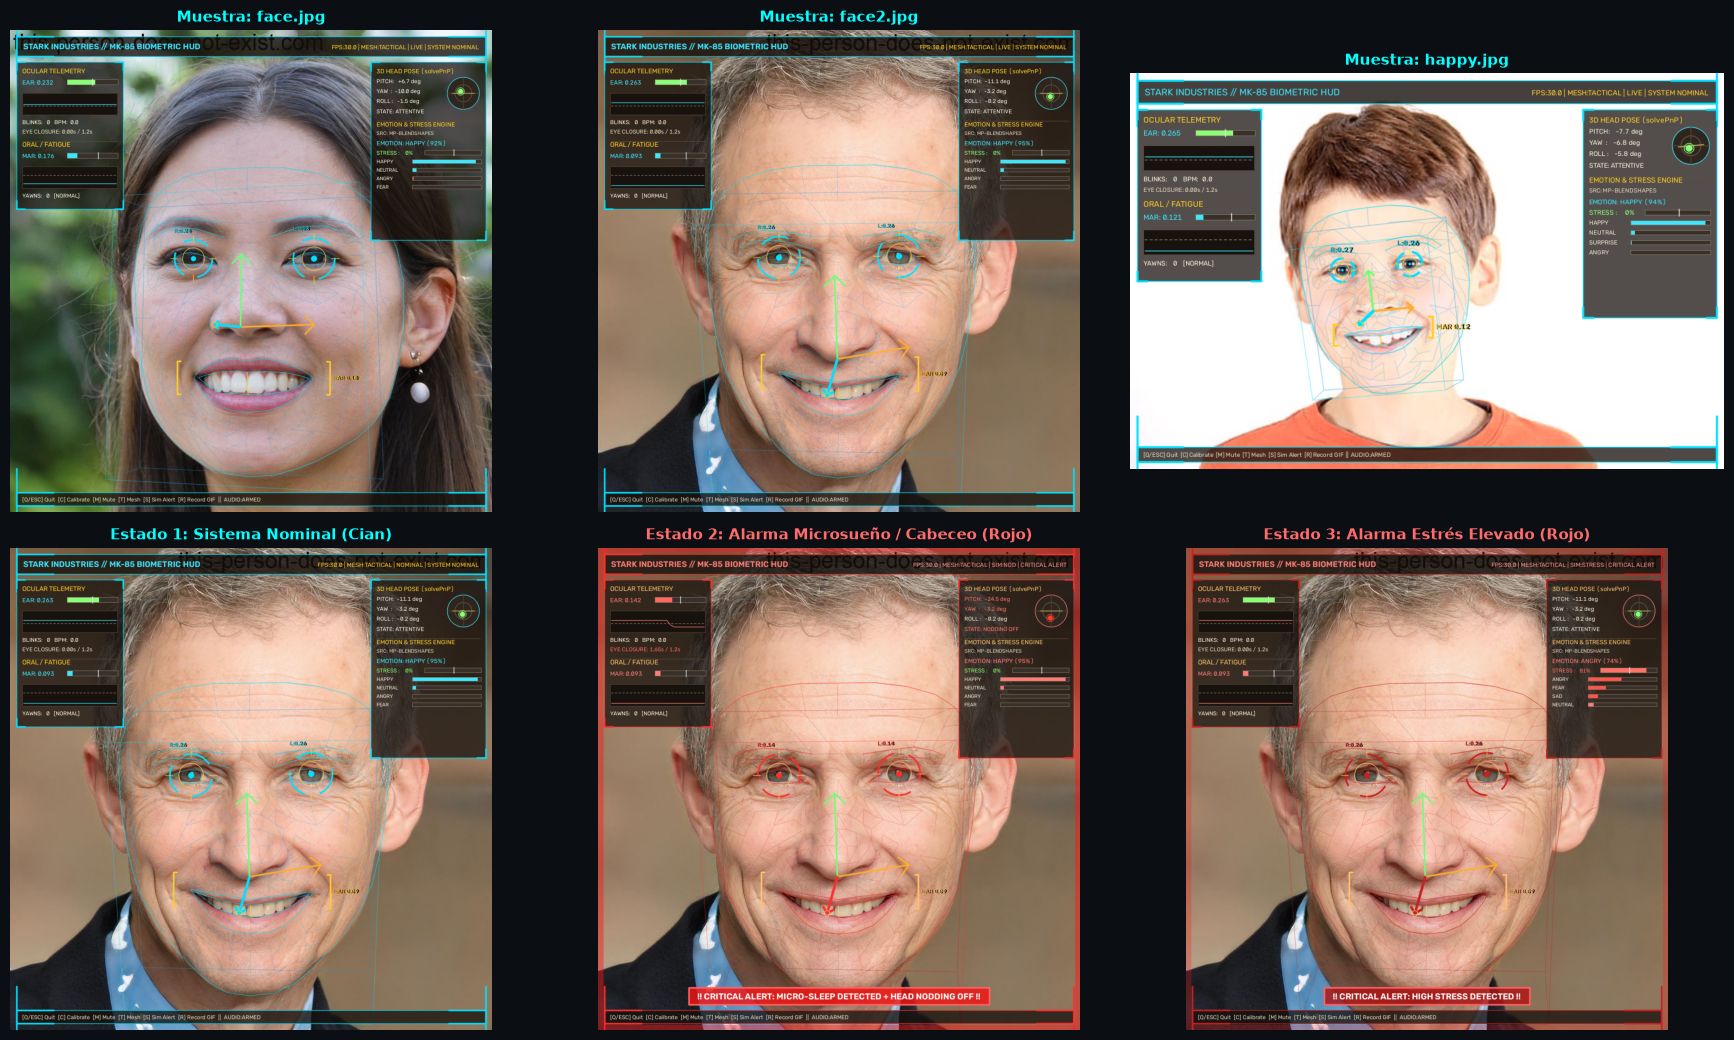

In [14]:
def _evaluate_sample_image(path: str, landmarker, tracker: BiometricTracker, emotion_engine: EmotionEngine, renderer: IronManHUDRenderer, alarm: AudioAlarm, t0: float) -> Tuple[str, np.ndarray]:
    tracker.reset()
    img = cv2.imread(path)
    res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))
    lms = res.face_landmarks[0] if res.face_landmarks else None
    bss = res.face_blendshapes[0] if res.face_blendshapes else None

    for step in range(18):
        bio = tracker.update(lms, img.shape, now=t0 + step * 0.04)
    emo = emotion_engine.update(img, bio.bbox, bss, now=t0 + 1.0)
    hud_img = renderer.render(img, bio, emo, fps=30.0, muted=alarm.muted, now=t0 + 1.0)

    print(
        f"[{Path(path).name}] EAR={bio.ear:.3f} | MAR={bio.mar:.3f} | "
        f"Pose(P={bio.pitch:+.1f}°, Y={bio.yaw:+.1f}°, R={bio.roll:+.1f}°) | "
        f"Emotion={emo.dominant_emotion} ({emo.confidence*100:.0f}%) | Stress={emo.stress_index:.2f}"
    )
    return Path(path).name, hud_img


def _build_simulated_states(landmarker, tracker: BiometricTracker, emotion_engine: EmotionEngine, renderer: IronManHUDRenderer) -> List[Tuple[str, np.ndarray]]:
    img = cv2.imread("faces/face2.jpg")
    res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))
    lms, bss = res.face_landmarks[0], res.face_blendshapes[0]

    tracker.reset()
    t_base = time.monotonic()
    for k in range(25):
        b_nom = tracker.update(lms, img.shape, now=t_base + k * 0.04)
    e_nom = emotion_engine.update(img, b_nom.bbox, bss, now=t_base + 1.0)
    hud_nom = renderer.render(img, b_nom, e_nom, fps=30.0, now=t_base + 1.0, sim_label="NOMINAL")

    b_nod = tracker.update(lms, img.shape, now=t_base + 2.0)
    b_nod.ear, b_nod.ear_left, b_nod.ear_right = 0.142, 0.140, 0.144
    b_nod.eye_closed, b_nod.eye_closed_duration, b_nod.micro_sleep = True, 1.65, True
    b_nod.pitch, b_nod.nodding_off = -24.5, True
    b_nod.ear_history = b_nod.ear_history[:-10] + [0.18] + [0.14] * 9
    hud_nod = renderer.render(img, b_nod, e_nom, fps=30.0, now=t_base + 2.1, sim_label="SIM:NOD")

    b_str = tracker.update(lms, img.shape, now=t_base + 3.0)
    e_str = EmotionState("angry", 0.74, {"angry": 0.48, "fear": 0.26, "sad": 0.14, "neutral": 0.08, "happy": 0.02, "surprise": 0.02}, 0.81, True, 1.8, e_nom.backend)
    hud_str = renderer.render(img, b_str, e_str, fps=30.0, now=t_base + 3.1, sim_label="SIM:STRESS")

    return [
        ("Estado 1: Sistema Nominal (Cian)", hud_nom),
        ("Estado 2: Alarma Microsueño / Cabeceo (Rojo)", hud_nod),
        ("Estado 3: Alarma Estrés Elevado (Rojo)", hud_str),
    ]


def _plot_showcase_grid(rendered_samples: List[Tuple[str, np.ndarray]], state_panels: List[Tuple[str, np.ndarray]]) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))
    fig.patch.set_facecolor("#0b0f14")
    for ax, (title, bgr) in zip(axes[0], rendered_samples):
        ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Muestra: {title}", color="cyan", fontsize=11, fontweight="bold")
        ax.axis("off")
    for ax, (title, bgr) in zip(axes[1], state_panels):
        ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
        ax.set_title(title, color="#ff6b6b" if "Alarma" in title else "cyan", fontsize=11, fontweight="bold")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def verify_and_showcase_hud() -> None:
    cfg = HUDConfig()
    tracker, emotion_engine, renderer = BiometricTracker(cfg), EmotionEngine(cfg), IronManHUDRenderer(cfg)
    alarm = AudioAlarm(cfg.alarm_wav_path, cfg.alarm_cooldown_seconds)

    with wave.open(cfg.alarm_wav_path, "rb") as wf:
        ch, sr, nf = wf.getnchannels(), wf.getframerate(), wf.getnframes()
    print(f"Audio alarma generado: {cfg.alarm_wav_path} (canales={ch}, {sr} Hz, {nf / sr:.2f}s)")

    opts = mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=cfg.model_path),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_faces=1,
        output_face_blendshapes=True,
    )
    with mp.tasks.vision.FaceLandmarker.create_from_options(opts) as landmarker:
        samples = [_evaluate_sample_image(p, landmarker, tracker, emotion_engine, renderer, alarm, time.monotonic() + i) for i, p in enumerate(["faces/face.jpg", "faces/face2.jpg", "faces/happy.jpg"])]
        states = _build_simulated_states(landmarker, tracker, emotion_engine, renderer)
    _plot_showcase_grid(samples, states)


verify_and_showcase_hud()


## 6. Lanzar HUD Interactivo en Tiempo Real (Webcam + Grabador de GIF)
Ejecuta la celda siguiente en tu equipo local con webcam conectada. Si entrenaste un modelo propio de emociones (por ejemplo `emotion_model.joblib` u `emotion_model.onnx`), indícalo en `custom_model_path`.


In [15]:
def _apply_sim_override(sim_mode: str, bio: BiometricState, emo: EmotionState) -> None:
    if sim_mode == "NOD":
        bio.nodding_off, bio.micro_sleep, bio.pitch, bio.ear = True, True, -24.0, 0.15
    elif sim_mode == "STRESS":
        emo.is_stressed, emo.stress_index, emo.dominant_emotion = True, 0.84, "angry"


def _record_gif_frame(hud_frame: np.ndarray, rec_frames: List[np.ndarray], now: float, rec_start: float, max_sec: float) -> bool:
    if (now - rec_start) > max_sec:
        return False
    if len(rec_frames) == 0 or (len(rec_frames) % 2 == 0):
        rh, rw = hud_frame.shape[:2]
        small = cv2.resize(hud_frame, (640, int(640 * rh / rw)))
        rec_frames.append(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
    return True


def _handle_keypress(
    key: int, bio: BiometricState, tracker: BiometricTracker, alarm: AudioAlarm,
    renderer: IronManHUDRenderer, sim_idx: int, sim_modes: Tuple[str, ...], recording: bool, rec_frames: List[np.ndarray]
) -> Tuple[bool, int, bool, float]:
    if key in (27, ord("q")):
        return True, sim_idx, recording, 0.0
    if key == ord("c") and bio.face_detected:
        off = tracker.calibrate_pose()
        print(f"Pose calibrada (offset P={off[0]:+.1f}°, Y={off[1]:+.1f}°, R={off[2]:+.1f}°)")
    elif key == ord("m"):
        alarm.muted = not alarm.muted
        print("Alarma silenciada:", alarm.muted)
    elif key == ord("t"):
        print("Modo malla:", renderer.cycle_mesh_mode())
    elif key == ord("s"):
        sim_idx = (sim_idx + 1) % len(sim_modes)
        print("Modo simulación:", sim_modes[sim_idx])
    elif key == ord("r"):
        if not recording:
            rec_frames.clear()
            print("Grabando demo GIF...")
            return False, sim_idx, True, time.monotonic()
        
        return False, sim_idx, False, 0.0
    
    return False, sim_idx, recording, 0.0


def _open_camera_and_options(camera_index: int, model_path: str):
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        print(f"No se pudo abrir la cámara {camera_index}. Verifica la conexión o usa otro índice.")
        return None, None
    
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
    opts = mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=model_path),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_faces=1,
        output_face_blendshapes=True,
    )
    
    return cap, opts


def _process_webcam_frame(
    frame: np.ndarray, landmarker, tracker: BiometricTracker, emotion_engine: EmotionEngine,
    alarm: AudioAlarm, renderer: IronManHUDRenderer, sim_mode: str, fps: float, ts_ms: int, recording: bool, now: float
) -> Tuple[np.ndarray, BiometricState]:
    res = landmarker.detect_for_video(
        mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)), ts_ms
    )
    bio = tracker.update(res.face_landmarks[0] if res.face_landmarks else None, frame.shape, now=now)
    emo = emotion_engine.update(frame, bio.bbox, res.face_blendshapes[0] if res.face_blendshapes else None, now=now)
    _apply_sim_override(sim_mode, bio, emo)
    if bio.micro_sleep or bio.nodding_off or emo.is_stressed:
        alarm.trigger(now=now)
    
    hud = renderer.render(frame, bio, emo, fps=fps, muted=alarm.muted, recording=recording, now=now, sim_label=sim_mode)
    return hud, bio


def run_ironman_hud(
    camera_index: int = 0,
    custom_model_path: Optional[str] = None,
    use_deepface: bool = False,
    record_gif_path: Optional[str] = None,
    max_record_seconds: float = 30.0,
) -> None:
    '''Ejecuta el HUD biométrico J.A.R.V.I.S. en tiempo real sobre la webcam.'''
    cfg = HUDConfig(custom_emotion_model_path=custom_model_path, use_deepface=use_deepface)
    ensure_face_landmarker_model(cfg.model_path)
    cap, opts = _open_camera_and_options(camera_index, cfg.model_path)
    if cap is None:
        return

    tracker, emotion_engine, renderer = BiometricTracker(cfg), EmotionEngine(cfg), IronManHUDRenderer(cfg)
    alarm = AudioAlarm(cfg.alarm_wav_path, cfg.alarm_cooldown_seconds)
    sim_modes, sim_idx = ("LIVE", "NOD", "STRESS"), 0
    recording, rec_frames = record_gif_path is not None, []
    rec_start, prev_t, fps, last_ts_ms = (time.monotonic() if recording else 0.0), time.monotonic(), 0.0, 0

    print("HUD activo. Pulsa 'q'/ESC para salir, 'c' calibrar pose, 's' simular alarma.")
    with mp.tasks.vision.FaceLandmarker.create_from_options(opts) as landmarker:
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            now = time.monotonic()
            fps = 0.85 * fps + 0.15 / max(now - prev_t, 1e-4) if fps > 0 else 1.0 / max(now - prev_t, 1e-4)
            prev_t, last_ts_ms = now, max(last_ts_ms + 1, int(now * 1000))

            hud_frame, bio = _process_webcam_frame(
                cv2.flip(frame, 1), landmarker, tracker, emotion_engine, alarm, renderer,
                sim_modes[sim_idx], fps, last_ts_ms, recording, now,
            )
            if recording:
                recording = _record_gif_frame(hud_frame, rec_frames, now, rec_start, max_record_seconds)

            cv2.imshow("J.A.R.V.I.S. // Iron-Man Biometric HUD", hud_frame)
            should_quit, sim_idx, recording, new_start = _handle_keypress(cv2.waitKey(1) & 0xFF, bio, tracker, alarm, renderer, sim_idx, sim_modes, recording, rec_frames)
            if new_start > 0.0:
                rec_start = new_start
            if should_quit:
                break

    cap.release()
    cv2.destroyAllWindows()
    if rec_frames:
        out_gif = record_gif_path or "ironman_hud_demo.gif"
        imageio.mimsave(out_gif, rec_frames, fps=12, loop=0)
        print(f"Demo GIF guardada en {out_gif} ({len(rec_frames)} frames).")


# Descomenta o ejecuta para lanzar con webcam en vivo:
run_ironman_hud(camera_index=0, custom_model_path=None, use_deepface=False)


HUD activo. Pulsa 'q'/ESC para salir, 'c' calibrar pose, 's' simular alarma.


W0000 00:00:1795257042.800837    5148 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1795257042.805411    5151 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795257042.817001    5152 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
qt.qpa.plugin: Could not find the Qt platform plugin "wayland" in "/home/skinnydevi/Development/computer-vision/P5/.venv/lib/python3.11/site-packages/cv2/qt/plugins"
